In [1]:
import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")   # a harmless warning from LAL
from gwpy.timeseries import TimeSeries
import matplotlib.pyplot as plt
import numpy as np
from gwpy.timeseries import TimeSeries
from gwpy.io.gwf import iter_channel_names

from pycbc.waveform import get_td_waveform
import pylab
from scipy.signal import welch
from pycbc.types import FrequencySeries

from pycbc.waveform import get_fd_waveform
from pycbc.filter import matched_filter
from scipy.signal import windows
from scipy.signal import iirnotch, filtfilt
from gwosc.datasets import event_gps
from pycbc.detector.ground import Detector

# Challenge 1: SNR Timeseries and Coalesence Time - Solutions

**Most common mistakes and corrections:**
- waveform models such as IMRPhenomD require you to input the **detector frame mass:** $m_{\text{det}} = m \: (1+z)$
- Since we care only about the positive frequencies in the data, we use np.fft.rfft() when going from time to frequency domain. As an effect, you also need to use np.fft.irfft() in the matched_filter_fft() function in order for your time steps in your SNR time series to span the whole observation time Tobs. (The hint in the challenge template was misleading for most of you.) You need to normalize the output of np.fft.irfft() with the number of frequency bins = len(time array)/2+1. 

In this challeng we are analyzing real LIGO data from the Hanford detector that includes the event GW170814 https://arxiv.org/pdf/1709.09660. 

**Task**: 
- Calculate a SNR time series using a template waveform with the masses of the binary as stated in the paper. 
- What is the coalesence time of that binary? 
- What SNR does this source have in the Hanford detector? 

Follow the template below to provide your answer. You can crosscheck your results with the findings in the paper. 

In [2]:
tevent = event_gps("GW170814")
segment = (int(tevent) - 16, int(tevent) + 16)
h1_ts = TimeSeries.fetch_open_data("H1", *segment, sample_rate=4096, cache=True, verbose=True)

gpstime = h1_ts.times.value
relative_times = gpstime - tevent

h1_np = np.array(h1_ts)#.bandpass(20,500))
dt = h1_ts.dt.value
Tobs = h1_ts.times.value[-1]-h1_ts.times.value[0]

Fetched 1 URLs from gwosc.org for [1186741845 .. 1186741877))
Reading data... [Done]


## Functions

The noise weighted inner product between two time series a and b is defined as $$(a|b) \equiv 4\, \mathrm{Re} \int_{0}^{\infty} \frac{\tilde{a}(f)\,\tilde{b}^{*}(f)}{S_n(f)}\, df $$
The matched filter SNR of a signal s with a template h is defined as  $$ \rho = \frac{(s|h)}{\sqrt{(h|h)}}$$
Calculating this SNR between the signal $s(t)$ and a time shifted template $h(t+\Delta t)$ leaves us with a SNR time series.$$ \frac{(s|h(t - \Delta t))}{\sqrt{(h|h)}} = \frac{4}{\sqrt{(h|h)}}\, \mathrm{Re} \int_{0}^{\infty} \frac{\tilde{s}(f)\,\tilde{h}^{*}(f)\, e^{2\pi i f \Delta t}}{S_n(f)} \, df .
$$ The SNR peak indicates the best line up between template and signal in time domain and thus tells us the most likely coalescence time given the template parameters and assuming a merger time of the template at t = 0. 
Make sure you use the non whitened verison so that this version of the inner product is correct! 

Notice that the above time shifted inner product looks like a fourier transform itsself! Use this in your calculation of the SNR for each time shift in order to speed up the calculation using np.fft.ifft(). Think about the normalization that is assumed here! https://numpy.org/doc/2.2/reference/routines.fft.html#module-numpy.fft

In [97]:
def inner_prod(a,b,psd,f):
    """
    a,b : signals to calculate the inner product of (already in frequency domain)
    psd: psd of the noise
    f: frequencies at which the signals & psd are evaluated
    """
    df = f[1]-f[0]
    a_np = np.array(a)
    b_np = np.array(b)
    psd_np = np.array(psd)
    return  4* np.real(np.sum(a_np* np.conjugate(b_np)/psd_np *df)) 

def matched_filter_fft(data_fd, template_fd, freq, psd):
    N_rfft = int(Tobs/dt)/2+1
    integrand = data_fd * np.conj(template_fd)/psd
    df = freq[1]-freq[0]
    ifft_integrand = np.fft.irfft(integrand)*df*N_rfft
    rho = 4*np.real(ifft_integrand/np.sqrt(inner_prod(template_fd,template_fd,psd,freq)))
    time_shifts = np.arange(0,len(ifft_integrand))*dt
    return time_shifts, rho

## The Data

Transform the numpy version of the time domain data to frequency domain using the fft. 

In [98]:
# ---- tranform the data to frequency domain -----
win = windows.tukey(len(h1_np), alpha=8/Tobs)                    
h1_fs = np.fft.rfft(h1_np* win) * dt 

freqs_values = np.fft.rfftfreq(n = len(h1_np),d = dt) # gives N/2+1 frequencies where N = len(h1_np)
df = freqs_values[1]-freqs_values[0]

In [112]:
len(h1_np)

131072

In [113]:
len(h1_fs)

65537

In [114]:
len(h1_np)/2+1

65537.0

We are not interested in all of the frequencies in our data. Only keep the data in the frequency window [20 Hz, 500 Hz]

## The PSD

Get the noise PSD from the offsource data. To do this, plot the time domain GW strain and identify the signals in the data using whitening and bandpassing techniques you learned about in the earlier Lab sessions. Decide on which part of the data to use to estimate the PSD of the detector noise. 

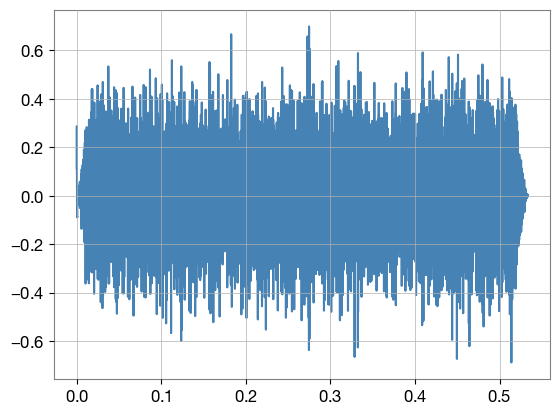

In [99]:
gpstime = h1_ts.times.value
gpstime_min = h1_ts.times.value/60
psd_crop = (gpstime_min < (tevent/60-0.02))
bandpass = (20, 100)
t_diff = gpstime_min-gpstime_min[0]
plt.plot(t_diff,h1_ts.whiten(4,2).bandpass(*bandpass),color = "steelblue")
#plt.plot(t_diff[psd_crop],h1_ts.whiten(4,2).bandpass(*bandpass)[psd_crop],color = "orange")


In [100]:
gpstime_min = h1_ts.times.value/60

In [101]:
psd_freqs, psd_welch = welch(h1_ts, fs=1/dt, nperseg=int(4 * 1/dt), average="median")
psd = np.interp(freqs_values, psd_freqs, psd_welch)

psd_freqs, psd_welch_left = welch(h1_ts[psd_crop], fs=1/dt, nperseg=int(4 * 1/dt), average="median")
# --- interpolate the psd so that it matched the frequency grid of the frequency domain data
psd_left = np.interp(freqs_values, psd_freqs, psd_welch_left)

psd_crop_right = (gpstime_min > (tevent/60+0.02))
psd_freqs, psd_welch_right = welch(h1_ts[psd_crop_right], fs=1/dt, nperseg=int(4 * 1/dt), average="median")
# --- interpolate the psd so that it matched the frequency grid of the frequency domain data
psd_right = np.interp(freqs_values, psd_freqs, psd_welch_right)


psd_crop_both = (gpstime_min > (tevent/60+0.02)) | (gpstime_min < (tevent/60-0.02))
psd_freqs, psd_welch_both = welch(h1_ts[psd_crop_both], fs=1/dt, nperseg=int(4 * 1/dt), average="median")
# --- interpolate the psd so that it matched the frequency grid of the frequency domain data
psd_both = np.interp(freqs_values, psd_freqs, psd_welch_both)

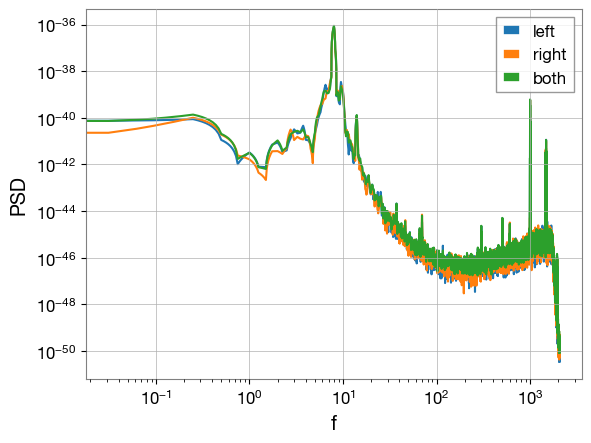

In [102]:
plt.loglog(freqs_values,psd_left,label = "left")
plt.loglog(freqs_values,psd_right,label = "right")
plt.loglog(freqs_values,psd_both, label = "both")
plt.ylabel("PSD")
plt.xlabel("f")
plt.legend()
plt.show()


## The waveform

Generate the GW waveform directly in frequency domain using the IMRPhenomD model. 

In [103]:
# ----- get the frequency domain template - generate it on the frequency grid of the data

#source parameters
z = 0.11
m_1 = 30.5*(1+0.11)
m_2 = 25.3*(1+0.11)
distance = 540 #Mpc
ra = 0.83
dec = 0.77 

d = Detector("H1")
Fp, Fc = d.antenna_pattern(ra, dec, 0, gpstime[0])
hp_fd, hc_fd = get_fd_waveform(approximant="IMRPhenomD", mass1=m_1, mass2=m_2, distance = distance, delta_f=df, f_lower=20, f_final=(1/dt) / 2) #still starts the waveform at 0, below 20 Hz it just sets it to zero
h_fd = hp_fd * Fp + hc_fd * Fc 

template_fd = np.zeros(len(freqs_values), dtype=complex)
template_fd = h_fd

In [104]:
len(hp_fd)

65537

## Compute the SNR timeseries

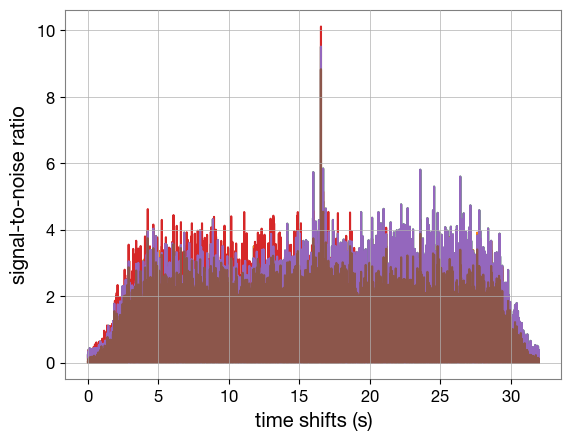

In [105]:
time_shifts,z = matched_filter_fft(h1_fs, template_fd, freqs_values, psd)
time_shifts,z_left = matched_filter_fft(h1_fs, template_fd, freqs_values, psd_left)
time_shifts,z_right = matched_filter_fft(h1_fs, template_fd, freqs_values, psd_right)
time_shifts,z_both = matched_filter_fft(h1_fs, template_fd, freqs_values, psd_both)

rho,rho_left,rho_right,rho_both = np.abs(z),np.abs(z_left),np.abs(z_right),np.abs(z_both)

plt.plot(time_shifts,rho)
plt.plot(time_shifts,np.abs(rho))
plt.plot(time_shifts,np.abs(rho_left))
plt.plot(time_shifts,np.abs(rho_right))
plt.plot(time_shifts,np.abs(rho_left))
plt.plot(time_shifts,np.abs(rho_both))

#plt.ylim(,0.01)
plt.ylabel('signal-to-noise ratio')
plt.xlabel('time shifts (s)')
plt.show()

In [116]:
len(time_shifts)

131072

In [106]:
print("No cropping: SNR = ",np.max(rho))
print("left offsource data: SNR = ",np.max(rho_left))
print("right offsource data: SNR = ",np.max(rho_right))
print("both offsource data: SNR = ",np.max(rho_both))

No cropping: SNR =  8.817214258108098
left offsource data: SNR =  9.510137033211995
right offsource data: SNR =  10.114059327666372
both offsource data: SNR =  8.829279411097264


In [117]:
t0 = gpstime[0]
i_peak = np.argmax(rho)                  # rho = |z| with the edges masked
dt_peak = time_shifts[i_peak]
t_event = t0 + dt_peak

print(f"t0 = {t0} s, Delta t = {dt_peak:.4f} s  ->  GPS time of merger in H1: {t_event:.4f} s, SNR = {rho[i_peak]:.2f}")

t0 = 1186741845.0 s, Delta t = 16.5349 s  ->  GPS time of merger in H1: 1186741861.5349 s, SNR = 8.82


In [118]:
dt

0.000244140625

In [119]:
print("From the paper: t_event= ",tevent)

From the paper: t_event=  1186741861.5


In [120]:
tevent-t_event

-0.034912109375